---
authors:
  - name: Hananeh Aliee
  - name: Amit Frishberg
  - name: Seo H. Kim
---


# Bulk deconvolution


(deconvolution-bulk-deconvolution-key-takeaway-1)=
## Introduction

Imagine tasting a fruit smoothie and trying to work out how much banana, strawberry and mango went into it.
You can't see the individual pieces anymore, everything has been blended into one average flavor.
But if you know what each fruit tastes like on its own, you can make a good guess at the recipe.

Bulk RNA-seq is the smoothie.
A tissue sample contains many different cell types, and sequencing it in bulk blends all their transcripts into one average expression profile.
Information about which cells contributed what is lost, which creates a real interpretation problem.
Let's say a gene goes up in diseased tissue compared to healthy tissue.
Two very different things could explain that {cite:p}`ShenOrr2013`:

- each cell is expressing more of the gene, or
- the cells that express the gene have become more common.


From the bulk profile alone, you can't tell these apart.
**Cell type deconvolution** recovers the recipe.
Given a bulk expression profile and a description of what each cell type "tastes like" (its typical expression profile, the *reference*), deconvolution estimates how much each cell type contributes to the sample {cite:p}`bd:Cobos2020`.

### Why not just use single-cell data?

You may start thinking: "We've been talking about single-cell analysis the whole time, why are we going back to bulk now?"
Although single-cell RNA-seq measures cell types directly, the bulk data already exists, and there is a lot of it.
Bulk RNA-seq is cheaper, easier to run in clinical settings, and decades of cohorts, biobanks and patient archives were profiled this way {cite:p}`bd:Cobos2023`.
Deconvolution lets you reuse a relatively small single-cell dataset as a reference to read cell composition out of thousands of bulk samples you could never afford to re-profile at single-cell resolution.

Single-cell data has also changed deconvolution itself.
Reference profiles used to come from physically sorted cell populations, which covered only the cell types someone thought to sort for, and only those with good antibodies {cite:p}`bd:Monaco2019,bd:Aran2017`.
Single-cell atlases now provide references for many tissues, organisms and conditions without that pre-selection {cite:p}`bd:Aliee2021,bd:Newman2019`.

### What makes it hard

The smoothie picture also shows where deconvolution breaks:

- **A missing ingredient.** If the smoothie contains kiwi but your list of fruits doesn't, its flavour gets wrongly attributed to whatever fruits *are* on the list.
A cell type absent from the reference distorts every other estimate {cite:p}`bd:Cobos2020, bd:Jin2021`.
- **Strong flavours dominate.** A small amount of a strong-tasting fruit can outweigh a lot of a mild one.
Likewise, cells differ in how much RNA they contain, so the estimated contribution to the *RNA* is not the same as the fraction of *cells* {cite:p}`bd:Monaco2019`.
<!-- - **The fruit itself changes.** A reference strawberry from one farm may not taste like the strawberry in your smoothie. Cell types in a diseased sample, or profiled on a different platform, may not express genes the way the reference says they do. -->

These caveats are the reason for the practical recommendations that follow.

(deconvolution-bulk-deconvolution-key-takeaway-2)=
## What makes deconvolution work: four rules of thumb

Going back to the smoothie: the quality of your recipe guess depends less on how clever you are and more on what you know about the fruit.
The same holds for deconvolution.
A large benchmark that systematically varied each step of the pipeline found that the choices that matter most are not the method itself but how the data and reference are prepared: keeping data on a linear scale, using a reference that covers every cell type in the mixture, and choosing marker genes sensibly {cite:p}`bd:Cobos2020`.
We restate these findings as four rules of thumb:

1. Include every cell type present in the sample in the reference.
2. Use a resolution at which cell types are actually distinguishable.
3. Keep the data in linear scale, and don't rescale it.
4. Choose marker genes carefully.

:::{dropdown} Four rules of thumb for deconvolution based on {cite:p}`bd:Cobos2020`
### 1. Include every cell type present in the sample in the reference

If an ingredient is missing from your list, its flavour does not disappear: it gets blamed on whatever fruits *are* on the list.
Leaving a cell type out of the reference that is present in the bulk sample made results substantially worse, no matter which method, transformation or normalization was used.
When you cannot be sure your reference is complete, prefer methods that explicitly estimate an "unknown" or "other" fraction (see the method table below).

### 2. Use a resolution at which cell types are actually distinguishable

Banana and strawberry are easy to tell apart in a smoothie; two kinds of raspberry are not.
Closely related cell types share most of their expression, so estimates for one leak into the other.
Benchmarks observe exactly this: signal is wrongly assigned to cell types that are absent from a mixture, likely because related cell types share signatures or because their marker genes are not specific enough.
More recent benchmarks likewise find that accuracy depends on how similar the cell types in the reference are {cite:p}`bd:Dietrich2026`.
In practice, start with broad cell types (T cells, B cells, monocytes) and only split them further if the finer types have clearly distinct expression.

### 3. Keep the data in linear scale, and don't rescale it

Mixing is additive: if a sample is 30% T cells and 70% monocytes, the T cells contribute 30% of the transcripts.
That additivity only holds for counts (or count-like values), not for log-transformed data, where adding two values no longer corresponds to mixing two samples.
Keeping the data in linear scale consistently gave the lowest errors, while log and variance-stabilizing transformations gave two- to four-fold higher median errors.

The same logic applies to scaling.
Rescaling genes or samples into a fixed range (0 to 1, or z-scores) throws away the actual amounts that deconvolution relies on, like setting every smoothie's strongest flavour to "maximum".
In the benchmark, these scalings and quantile normalization performed poorly, while standard library-size normalizations mattered little for most methods.

```{important}
**Do:** keep counts in linear scale and use a standard library-size normalization.
**Avoid:** log or variance-stabilizing transformation, row scaling, column min-max, column z-score and quantile normalization.
```

### 4. Choose marker genes carefully

Not every fruit is useful for telling a recipe apart: water content tastes the same in all of them.
Genes expressed at similar levels in every cell type carry no information about composition and only add noise.
Marker selection was one of the three most influential factors for classical (non-single-cell) deconvolution methods.
A useful marker is not just high in its own cell type; it is clearly higher than in the *runner-up*, the cell type with the second-highest expression.
The benchmark recommends a stringent selection built on exactly this comparison, in line with earlier findings that markers work best when expressed mainly in one cell type {cite:p}`bd:Hunt2018` and when genes with a small fold change between the top two cell types are removed {cite:p}`bd:Monaco2019`.
Within such a marker set, using all markers worked best, and picking only a handful per cell type (e.g. the top two) could be worse than random for some methods.
Good marker genes are high in one cell type and low in the others; feature-selection tools such as AutoGeneS pick genes that make cell types as distinguishable as possible {cite:p}`bd:Aliee2021`.
:::

(deconvolution-bulk-deconvolution-key-takeaway-3)=
## What the benchmarks say

Deconvolution methods have been compared many times, on immune cells {cite:p}`bd:Sturm2019`, on pseudo-bulk mixtures built from single-cell data {cite:p}`bd:Cobos2020`, under varied simulation settings {cite:p}`bd:Jin2021`, in tumours {cite:p}`bd:Tran2023`, on paired bulk and single-cell data {cite:p}`bd:Cobos2023`, and across transcriptomic and methylation data {cite:p}`bd:Amblard2025`.

A few lessons hold across them:

- **No method wins everywhere.** The most recent large benchmark of single-cell-informed methods found substantial differences in accuracy, scalability and robustness that depended on cell-type similarity, reference composition and where the data came from {cite:p}`bd:Dietrich2026`.
- **Single-cell references are competitive.** Methods that use scRNA-seq references performed comparably to the best classical methods, while semi-supervised approaches had higher errors {cite:p}`bd:Cobos2020`.
- **Fine-grained types are where methods diverge.** In breast tumours, most methods mistook normal epithelial cells for cancer cells as tumour purity rose; BayesPrism and DWLS made the fewest false calls and did best on granular immune lineages {cite:p}`bd:Tran2023`.
- **The reference matters as much as the method.** Profiling bulk and single-cell data from the same samples improved both single-cell preprocessing and deconvolution accuracy {cite:p}`bd:Cobos2023`.

The practical takeaway: run more than one method, check whether they agree, and validate against any measured proportions you have (for example, blood counts or histology).

## Method families

Most methods differ in *how* they turn the reference and the bulk profile into proportions.
The table groups them by that idea; expand each family for details and examples.

| Family | Core idea (smoothie version) | Needs a full reference? | Output | Examples |
|---|---|---|---|---|
| Regression | Find the mix of reference fruits whose blend tastes closest to the smoothie | Yes | Proportions | CIBERSORTx, MuSiC, DWLS, FARDEEP, Bisque, SCDC |
| Enrichment / marker scores | Score how strongly each fruit's signature flavour comes through, one fruit at a time | Marker lists only | Scores (not always proportions) | xCell, MCP-counter |
| Bayesian | Treat each fruit's taste as uncertain and infer the most probable recipe, plus how each fruit tasted in *this* smoothie | Yes (used as a prior) | Proportions + per-cell-type expression | BayesPrism |
| Deep learning | Train a model on thousands of smoothies with known recipes, then predict | Yes (to simulate training data) | Proportions | Scaden |
| Reference-free | Recover both the ingredients and the recipe from many smoothies at once | No | Proportions + inferred profiles | Linseed |

:::{dropdown} Methods-Citations
Here are the citations for the examples in the table above:

Regression:
- **CIBERSORTx** {cite:p}`bd:Newman2019`}
- **MuSiC** {cite:p}`bd:WangXuran2019`}
- **DWLS** {cite:p}`bd:Tsoucas2019`}
- **FARDEEP** {cite:p}`bd:Hao2019`}
- **Bisque** {cite:p}`bd:Jew2020`}
- **SCDC** {cite:p}`bd:Dong2020`}
- **dtangle** {cite:p}`bd:Hunt2018`}
- **SQUID** {cite:p}`bd:Cobos2023`}

Enrichment / marker scores:
- **xCell** {cite:p}`bd:Aran2017`}
- **MCP-counter** {cite:p}`bd:Becht2016`}

Bayesian:
- **BayesPrism** {cite:p}`bd:Chu2022`

Deep learning:
- **Scaden** {cite:p}`bd:Menden2020`}

Reference-free:
- **Linseed** {cite:p}`bd:Zaitsev2019`}
:::

:::{dropdown} Strengths and weaknesses of method families
| Family | Strengths | Weaknesses |
|---|---|---|
| Regression | Interpretable and fast | Sensitive to missing cell types and to highly similar cell types |
| Enrichment / marker scores | Robust; need only marker lists | Scores are not proportions; accuracy drops when many related cell types are scored |
| Bayesian | Can model uncertainty and per-cell-type expression | Slower and more complex |
| Deep learning | Can learn complex relationships | Needs a lot of training data; may not generalize well |
| Reference-free | No reference needed | Needs many samples; components must be labelled as cell types afterwards |
:::

Among the many available deconvolution tools, we use **Rectangle** {cite:p}`bd:Eder2026` to demonstrate a use case.
Rectangle is a Python framework from the scverse ecosystem that learns cell-type signatures directly from an annotated single-cell reference.

:::{admonition} Input requirements
:class: note

- **Single-cell reference:** an `AnnData` object with **unnormalized counts** (cells × genes) and cell-type labels in `adata.obs["cell_type"]` (or another column, set with `cell_type_col`).
- **Bulk data:** a `pandas.DataFrame` with **samples as rows and genes as columns**, in **TPM**. Note that this is the transpose of the common genes × samples layout, so you may need `bulks.T`.
- **Gene names** must use the same naming scheme in both datasets (e.g. both gene symbols).

Both inputs stay in linear scale, in line with rule 3.
:::

The output is a samples × cell types table of estimated proportions, with an additional `Unknown` column.

## Deconvolving bulk COVID-19 whole blood samples

In the following use case we deconvolve 49 bulk whole blood RNA-seq samples from 39 patients with COVID-19 and 10 healthy controls {cite:p}`bd:Aschenbrenner2020` using Rectangle {cite:p}`bd:Eder2026`.
As single-cell reference, we use whole blood scRNA-seq data of patients with COVID-19 and controls {cite:p}`bd:Schulte-Schrepping2020`.
For most of the patients, neutrophil and lymphocyte counts were measured in the clinic, which lets us check the estimates against an independent measurement.

### Environment setup

In [1]:
import lamindb as ln
import matplotlib.pyplot as plt
import pandas as pd
import rectanglepy as rectangle
import scanpy as sc
import seaborn as sns
from scipy import stats

ln.connect("theislab/sc-best-practices")

ln.track("HsJRsKmLcB2Q")

→ connected lamindb: theislab/sc-best-practices


! It looks like you are running jupyter lab but don't have jupyter-server module installed. Please install it via pip install jupyter-server


→ loaded Transform('HsJRsKmLcB2Q0002', key='bulk_deconvolution.ipynb'), started new Run('8POULixJNZAVUB4P') at 2026-11-09 12:26:05 UTC


### Loading the data

All three datasets are stored in the lamindb instance of this book.
The bulk expression is already converted to TPM, with one row per sample and one column per gene, which is the layout Rectangle expects.

In [2]:
bulks = ln.Artifact.get(
    key="deconvolution/bulk_deconvolution/covid19_wholeblood_bulk_tpm.parquet"
).load()
metadata = ln.Artifact.get(
    key="deconvolution/bulk_deconvolution/covid19_wholeblood_metadata.parquet"
).load()
bulks.iloc[:5, :5]

gene_symbol,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1
sample_id,,,,,
9088,0.147677,2.835530,0.0,0.166511,17.147886
9097,0.516158,6.270650,0.0,0.303118,17.110516
9098,0.430991,4.551008,0.0,0.196347,12.596429
9099,0.200912,3.315492,0.0,0.038724,9.979159
9100,0.178867,4.216448,0.0,0.261436,14.773787


The metadata tells us whether a sample comes from a patient or a healthy control, together with the measured blood counts.

In [3]:
metadata[
    ["status", "Total.neutrophil.count...mm3.", "Total.lymphocyte.count...mm3."]
].head()

,status,Total.neutrophil.count...mm3.,Total.lymphocyte.count...mm3.
sample_id,,,
9088,covid,12010.0,1271.0
9097,covid,5388.0,753.0
9098,covid,3847.0,555.0
9099,covid,4871.0,793.0
9100,covid,4320.0,864.0


In [4]:
adata = ln.Artifact.get(
    key="deconvolution/bulk_deconvolution/schulte_schrepping2020_covid19_wholeblood_counts.h5ad"
).load()
adata

AnnData object with n_obs × n_vars = 89883 × 33417
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'nCount_HTO', 'nFeature_HTO', 'percent.mito', 'percent.hb', 'HTO_maxID', 'HTO_secondID', 'HTO_margin', 'HTO_classification', 'HTO_classification.global', 'hash.ID', 'demultID', 'donor', 'onset_of_symptoms', 'days_after_onset', 'sampleID', 'date_of_sampling', 'experiment', 'cartridge', 'platform', 'purification', 'cells', 'age', 'sex', 'group_per_sample', 'who_per_sample', 'disease_stage', 'diagnosis', 'oxygen', 'outcome', 'comorbidities', 'COVID.19.related_medication_and_anti.microbials', 'primary_complaint', 'RNA_snn_res.0.8', 'cluster_labels_res.0.8', 'new.order', 'hpca.labels', 'blueprint.labels', 'monaco.labels', 'immune.labels', 'dmap.labels', 'hemato.labels'
    obsm: 'X_umap'

### Preparing the single-cell reference

The study profiled both fresh whole blood and peripheral blood mononuclear cells (PBMCs).
PBMC isolation removes granulocytes such as neutrophils, which make up most of the white blood cells in whole blood.
Since our bulk samples are whole blood, the reference only contains the whole blood cells, so that it covers every cell type in the mixture (rule 1).
`adata.X` holds the unnormalized counts that Rectangle expects.

In [5]:
adata.obs["cluster_labels_res.0.8"].value_counts()

cluster_labels_res.0.8
Neutrophils_1             22714
Neutrophils_2             18675
Neutrophils_3              9986
CD4_T_cells_1              6278
CD14_Monocytes_1           5362
Neutrophils_4              4710
CD8_T_cells                3255
Megakaryocytes             3180
NK_cells                   2916
B_cells_1                  2561
CD4_T_cells_2              1917
Mixed_cells                1727
Immature Neutrophils_1     1317
CD16_Monocytes              983
Immature Neutrophils_2      981
CD14_Monocytes_3            632
Eosinophils                 579
CD14_Monocytes_2            556
CD4_T_cells_3               409
Plasmablast                 390
Prol. cells                 247
mDC                         235
B_cells_2                   138
pDC                          86
CD34+ GATA2+ cells           49
Name: count, dtype: int64

Quality control has already been performed by the authors, so we skip it here.
We remove two clusters that do not represent a single cell type: `Mixed_cells`, which express markers of several cell types and are likely doublets, and dividing cells (`Prol. cells`), which are grouped by their cell-cycle genes rather than their identity.
Rectangle builds one expression profile per cell type, and these clusters would blend the profiles of others.

The authors annotated the data at a fine resolution: there are four neutrophil clusters, three CD4⁺ T cell clusters and three CD14⁺ monocyte clusters.
These clusters are states of the same cell type and differ in only a few genes, which is too little to tell them apart in a bulk profile (rule 2).
We therefore merge the clusters of each cell type into a single label.

In [6]:
cell_types = {
    "Neutrophils_1": "Neutrophils",
    "Neutrophils_2": "Neutrophils",
    "Neutrophils_3": "Neutrophils",
    "Neutrophils_4": "Neutrophils",
    "Immature Neutrophils_1": "Immature neutrophils",
    "Immature Neutrophils_2": "Immature neutrophils",
    "Eosinophils": "Eosinophils",
    "CD14_Monocytes_1": "CD14 monocytes",
    "CD14_Monocytes_2": "CD14 monocytes",
    "CD14_Monocytes_3": "CD14 monocytes",
    "CD16_Monocytes": "CD16 monocytes",
    "mDC": "mDCs",
    "pDC": "pDCs",
    "CD4_T_cells_1": "CD4 T cells",
    "CD4_T_cells_2": "CD4 T cells",
    "CD4_T_cells_3": "CD4 T cells",
    "CD8_T_cells": "CD8 T cells",
    "NK_cells": "NK cells",
    "B_cells_1": "B cells",
    "B_cells_2": "B cells",
    "Plasmablast": "Plasmablasts",
    "Megakaryocytes": "Megakaryocytes",
    "CD34+ GATA2+ cells": "CD34+ GATA2+ cells",
}

adata = adata[adata.obs["cluster_labels_res.0.8"].isin(cell_types)].copy()
adata.obs["cell_type"] = (
    adata.obs["cluster_labels_res.0.8"].map(cell_types).astype("category")
)
adata.obs["cell_type"].value_counts()

cell_type
Neutrophils             56085
CD4 T cells              8604
CD14 monocytes           6550
CD8 T cells              3255
Megakaryocytes           3180
NK cells                 2916
B cells                  2699
Immature neutrophils     2298
CD16 monocytes            983
Eosinophils               579
Plasmablasts              390
mDCs                      235
pDCs                       86
CD34+ GATA2+ cells         49
Name: count, dtype: int64

The authors also computed a {term}`UMAP <Uniform manifold approximation and projection (UMAP)>` embedding, which we use to look at the cell types in the reference.

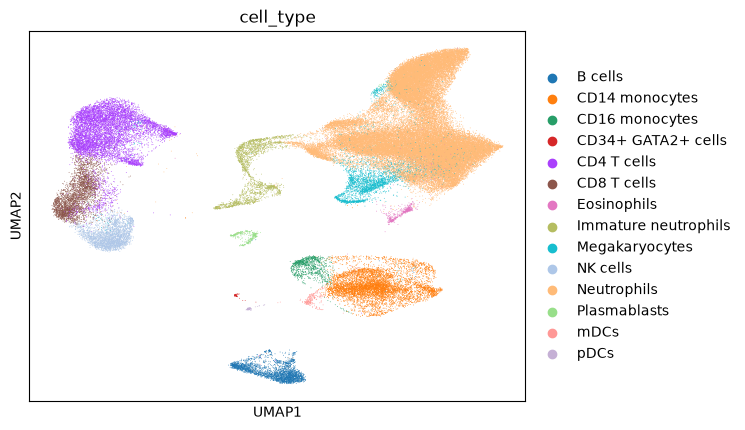

In [7]:
sc.pl.umap(adata, color="cell_type")

### Running Rectangle

A single call to `rectangle.rectangle` builds the reference and deconvolves all bulk samples.
Under the hood, it:

1. sums the counts of all cells of a cell type into a pseudobulk profile, the cell type's "taste",
2. selects marker genes by differential expression between the cell types, and tunes the cutoffs on simulated mixtures with known proportions (rule 4),
3. groups similar cell types into clusters, deconvolves the clusters first and then the cell types within them, which helps with closely related cell types (rule 2),
4. corrects for the different amounts of RNA per cell, so that the output are fractions of cells and not of RNA,
5. estimates how much of each bulk sample is not explained by the reference and reports it as `Unknown` (rule 1).

Rectangle uses only the genes measured in both datasets.
Selecting marker genes is the slow part and takes a while on a reference of this size.

In [8]:
fractions, signatures = rectangle.rectangle(adata, bulks, cell_type_col="cell_type")

2026-11-09 13:26:15.419 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 21225 common genes between bulks and single-cell data


2026-11-09 13:26:18.432 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis


2026-11-09 13:26:19.052 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells


2026-11-09 13:26:21.029 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for CD14 monocytes


2026-11-09 13:26:22.173 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for CD16 monocytes


2026-11-09 13:26:23.529 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for CD34+ GATA2+ cells


... (66 outputs left out)

2026-11-09 13:26:52.428 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 39
2026-11-09 13:26:52.440 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 34
2026-11-09 13:26:52.443 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 45
2026-11-09 13:26:52.474 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 46
2026-11-09 13:26:52.482 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 37
2026-11-09 13:26:52.506 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 47
2026-11-09 13:26:52.571 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 41
2026-11-09 13:26:52.580 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 48
2026-11-09 13:26:52.606 | IN

2026-11-09 13:26:53.022 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 44


2026-11-09 13:26:53.289 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 45
2026-11-09 13:26:53.365 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 47
2026-11-09 13:26:53.391 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 48
2026-11-09 13:26:53.454 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 42
2026-11-09 13:26:53.482 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 43


2026-11-09 13:26:53.502 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 46


The returned `signatures` summarizes the reference that Rectangle built, including how many marker genes it selected per cell type and which cell types it grouped together.

In [9]:
signatures

RectangleSignatureResult
──────────────────────────────────────────────────
  Total Signature genes: 466
  Cell types: 14
    B cells marker genes: ['AFF3', 'BANK1', 'BIRC3', 'CD22', 'CD37', 'CD79A', 'CD79B', 'FCMR', 'FCRL1', 'HLA-DOB', 'HVCN1', 'IGHD', 'IKZF3', 'LINC00926', 'MEF2C', 'MS4A1', 'PAX5', 'PLPP5', 'RALGPS2', 'TNFRSF13C']
    CD14 monocytes marker genes: ['APLP2', 'CCR1', 'CD14', 'CD163', 'CD300E', 'CD33', 'CD36', 'CD68', 'CD93', 'CPVL', 'CSTA', 'CTSB', 'CTSS', 'CYP1B1', 'DUSP6', 'FCN1', 'KCTD12', 'LGALS3', 'LRP1', 'MAFB', 'MS4A6A', 'PLBD1', 'SLC7A7', 'TMEM176A', 'TMEM176B', 'VCAN', 'ZNF385A']
    CD16 monocytes marker genes: ['ABI3', 'ADGRE1', 'AIF1', 'CD300E', 'CD68', 'CD86', 'CDKN1C', 'COTL1', 'CSF1R', 'CTSL', 'CUX1', 'CXCL16', 'FAM110A', 'FCGR3A', 'HMOX1', 'IER5', 'INSIG1', 'KDM1B', 'KLF4', 'LILRA1', 'LILRB1', 'LILRB2', 'LRRC25', 'LST1', 'MAFB', 'MS4A4A', 'MS4A7', 'MTSS1', 'NAAA', 'NAGA', 'NR4A1', 'PECAM1', 'PLXNB2', 'POU2F2', 'RHOC', 'RRAS', 'SCIMP', 'SIDT2', 'SIGLEC10'

### Outputs

The main output of all cell type deconvolution methods is a samples × cell types matrix of estimated proportions.
Each row sums to one, and Rectangle adds the `Unknown` column for content that the reference does not explain.

In [10]:
fractions.round(3).head()

,B cells,CD14 monocytes,CD16 monocytes,CD34+ GATA2+ cells,CD4 T cells,CD8 T cells,Eosinophils,Immature neutrophils,Megakaryocytes,NK cells,Neutrophils,Plasmablasts,mDCs,pDCs,Unknown
sample_id,,,,,,,,,,,,,,,
9088,0.035,0.032,0.000,0.000,0.067,0.039,0.011,0.041,0.295,0.038,0.381,0.044,0.000,0.000,0.017
9097,0.014,0.061,0.000,0.000,0.022,0.024,0.000,0.001,0.103,0.054,0.685,0.037,0.000,0.000,0.000
9098,0.002,0.075,0.001,0.000,0.033,0.067,0.005,0.003,0.167,0.025,0.493,0.073,0.001,0.002,0.055
9099,0.004,0.142,0.000,0.001,0.076,0.022,0.019,0.010,0.147,0.048,0.523,0.006,0.000,0.001,0.000
9100,0.047,0.029,0.000,0.001,0.049,0.016,0.002,0.012,0.087,0.027,0.684,0.047,0.000,0.001,0.000


A stacked bar per sample gives an overview of the estimated composition.

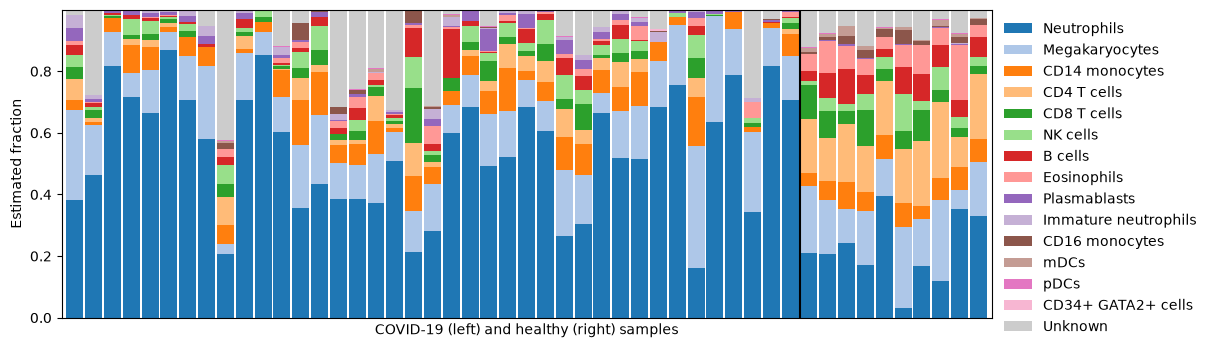

In [11]:
order = (
    fractions.mean()
    .sort_values(ascending=False)
    .index.drop("Unknown")
    .append(pd.Index(["Unknown"]))
)
samples = metadata.sort_values("status").index
colors = sns.color_palette("tab20", len(order) - 1) + [(0.8, 0.8, 0.8)]

ax = fractions.loc[samples, order].plot.bar(
    stacked=True, width=0.9, figsize=(12, 4), color=colors
)
n_covid = (metadata["status"] == "covid").sum()
ax.axvline(n_covid - 0.5, color="black")
ax.set_xticks([])
ax.set_xlabel("COVID-19 (left) and healthy (right) samples")
ax.set_ylabel("Estimated fraction")
ax.legend(bbox_to_anchor=(1, 1), loc="upper left", frameon=False)
plt.show()

Neutrophils make up the largest part of most patient samples.
Two other columns need a closer look.

The `Megakaryocytes` cluster of the reference mostly captures platelets, fragments of megakaryocytes that circulate in large numbers in the blood.
Platelets far outnumber white blood cells but carry little RNA, so their estimated fraction depends strongly on the correction for RNA content.
Clinical blood counts, in contrast, only cover white blood cells.

The `Unknown` column is the part of each sample that the reference does not explain.
Whole blood contains cell types that are missing from the single-cell reference, for example red blood cell precursors, which contribute globin transcripts to the bulk RNA.
Without an `Unknown` column, their expression would be assigned to the cell types in the reference (rule 1).


### Validating against blood counts

If the true proportions are known, we can check the estimates against them.
The patients' neutrophil and lymphocyte counts were measured in the clinic, for the healthy controls they are missing.
The counts are absolute numbers per mm³ of blood, while deconvolution estimates relative fractions, so we compare the share of neutrophils among neutrophils and lymphocytes.
This ratio is also unaffected by platelets and by the `Unknown` fraction, which the blood counts do not include.

Pearson r = 0.68 (p = 2.2e-05, n = 32 samples)


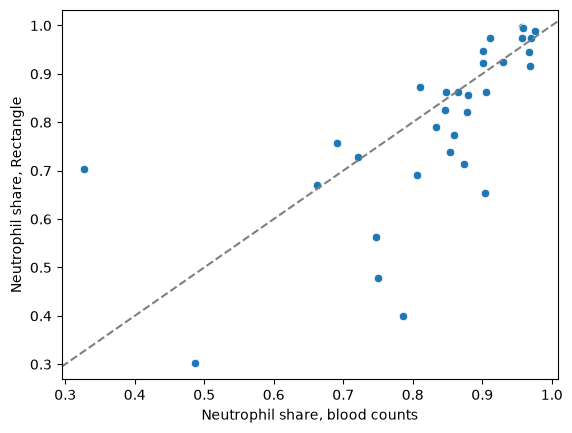

In [12]:
lymphocytes = ["CD4 T cells", "CD8 T cells", "NK cells", "B cells", "Plasmablasts"]
neutrophils = ["Neutrophils", "Immature neutrophils"]

measured = metadata["Total.neutrophil.count...mm3."] / (
    metadata["Total.neutrophil.count...mm3."]
    + metadata["Total.lymphocyte.count...mm3."]
)
estimated = fractions[neutrophils].sum(axis=1) / fractions[
    neutrophils + lymphocytes
].sum(axis=1)

validation = pd.DataFrame({"measured": measured, "estimated": estimated}).dropna()
r, p = stats.pearsonr(validation["measured"], validation["estimated"])
print(f"Pearson r = {r:.2f} (p = {p:.1e}, n = {len(validation)} samples)")

ax = sns.scatterplot(data=validation, x="measured", y="estimated")
ax.axline((0.5, 0.5), slope=1, color="grey", linestyle="--")
ax.set_xlabel("Neutrophil share, blood counts")
ax.set_ylabel("Neutrophil share, Rectangle")
plt.show()

The estimated and measured neutrophil shares agree well, with most samples close to the diagonal.
A few samples are off by more than 0.2, so the estimates of individual samples should be interpreted with care.

### Comparing COVID-19 patients and healthy controls

We can also look for changes in cell type composition between patients and healthy controls.
For each cell type, we compare the estimated fractions with a Mann-Whitney U test and correct the p-values for testing many cell types.
Keep in mind that the fractions of a sample sum to one, so an increase in one cell type forces others to decrease.
The chapter on [compositional analysis](../conditions/compositional.ipynb) explains how to test for changes in composition while taking this into account.

In [13]:
covid = metadata["status"] == "covid"
tests = pd.DataFrame(
    {
        "mean covid": fractions[covid].mean(),
        "mean healthy": fractions[~covid].mean(),
        "p": [
            stats.mannwhitneyu(
                fractions.loc[covid, ct], fractions.loc[~covid, ct]
            ).pvalue
            for ct in fractions.columns
        ],
    }
)
tests["p adj"] = stats.false_discovery_control(tests["p"])
tests.sort_values("p adj").round({"mean covid": 3, "mean healthy": 3})

,mean covid,mean healthy,p,p adj
CD4 T cells,0.032,0.177,0.000002,0.000023
Eosinophils,0.012,0.076,0.000004,0.000027
mDCs,0.001,0.012,0.000005,0.000027
CD16 monocytes,0.004,0.019,0.000053,0.000154
Immature neutrophils,0.011,0.001,0.000058,0.000154
Neutrophils,0.545,0.223,0.000062,0.000154
B cells,0.022,0.068,0.000076,0.000163
Plasmablasts,0.015,0.002,0.000208,0.000391
CD8 T cells,0.028,0.065,0.000539,0.000898
CD34+ GATA2+ cells,0.000,0.000,0.010665,0.015998


We plot four of the cell types that change significantly between the groups.
CD4⁺ T cells and eosinophils have the smallest p-values.
Neutrophils show the largest change and are the cell type we validated against the blood counts above.
Immature neutrophils increase the most relative to their level in healthy blood.
mDCs and CD16 monocytes also change significantly, but we leave them out because they make up less than 2% of the cells, and deconvolution is least reliable for rare cell types {cite:p}`bd:Tsoucas2019`.


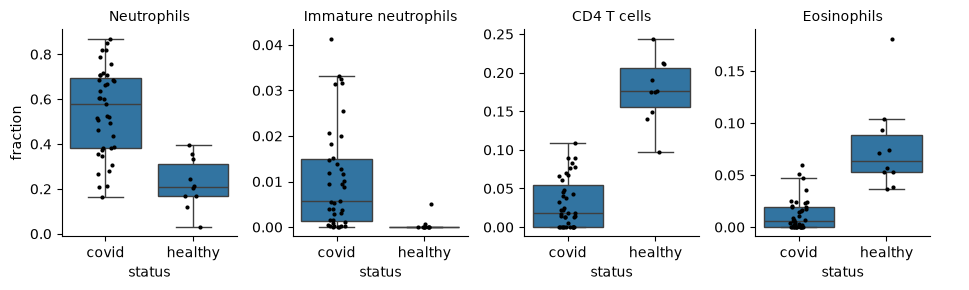

In [14]:
selected = ["Neutrophils", "Immature neutrophils", "CD4 T cells", "Eosinophils"]
plot_df = (
    fractions[selected]
    .join(metadata["status"])
    .melt(id_vars="status", var_name="cell type", value_name="fraction")
)

g = sns.catplot(
    data=plot_df,
    x="status",
    y="fraction",
    col="cell type",
    kind="box",
    showfliers=False,
    sharey=False,
    height=3,
    aspect=0.8,
)
g.map_dataframe(sns.stripplot, x="status", y="fraction", color="black", size=3)
g.set_titles("{col_name}")
plt.show()

Compared to the healthy controls, the patients have more neutrophils, including immature neutrophils, and fewer CD4⁺ T cells and eosinophils.
The table shows the same direction for B cells and CD8⁺ T cells.
Immature neutrophils are rare in healthy blood, and the single-cell study also found them in patients with severe COVID-19 {cite:p}`bd:Schulte-Schrepping2020`.
With 10 controls and fractions that depend on each other, these results describe the cohort rather than establish effects, and a dedicated compositional analysis would be the next step.

In [15]:
ln.finish()

! cells [(1, 4), (14, 13)] were not run consecutively


→ to save the notebook html, run: lamin save /home/seokim/seocodes_linux/single-cell-best-practices/jupyter-book/deconvolution/bulk_deconvolution.ipynb


→ finished Run('8POULixJNZAVUB4P') after 52s at 2026-11-09 12:26:58 UTC


→ go to: https://lamin.ai/theislab/sc-best-practices/run/8POULixJNZAVUB4P


→ to update your notebook from the CLI, run: lamin save /home/seokim/seocodes_linux/single-cell-best-practices/jupyter-book/deconvolution/bulk_deconvolution.ipynb


## Limitations and traps

The [four rules of thumb](#deconvolution-bulk-deconvolution-key-takeaway-2) cover the most common sources of error.
Our example of deconvolving bulk COVID-19 whole blood samples shows a few more traps:

- **Fractions of cells are not fractions of RNA.** Converting between the two relies on an estimate of each cell type's RNA content, so the fractions of cell types with little RNA, such as platelets (`Megakaryocytes`), are uncertain.
- **The reference is not the sample.** Differences in patients, technology or disease state change gene expression and get attributed to the wrong cell types; a reference from the same samples helps {cite:p}`bd:Cobos2023`.
- **Unknown content is estimated, not identified.** The `Unknown` column tells you how much of a sample the reference misses, but not which cells {cite:p}`bd:Cobos2020,bd:Jin2021`.
- **Trust cohort trends more than single samples.** A few samples were off by more than 0.2, rare cell types are the least reliable {cite:p}`bd:Tsoucas2019`, and fractions are [compositional](../conditions/compositional.ipynb).

## New directions

Deconvolution methods are moving beyond cell type proportions:

- **Cell-type-specific expression.** BayesPrism {cite:p}`bd:Chu2022` and CIBERSORTx {cite:p}`bd:Newman2019` also estimate each cell type's expression in each sample, which tells apart more expression per cell from more cells.
- **Marker gene selection.** AutoGeneS {cite:p}`bd:Aliee2021` selects genes that make cell types as distinguishable as possible, without prior knowledge of markers.
- **Cell states.** CPM {cite:p}`bd:Frishberg2019` deconvolves the variation within cell types, such as shifts along a cellular trajectory.
- **Spatial transcriptomics.** Each spot captures several cells and is deconvolved like a small bulk sample, see the chapter on [spatial deconvolution](../spatial/deconvolution.ipynb).

## Contributors

We gratefully acknowledge the contributions of:

### Authors

* Hananeh Aliee
* Amit Frishberg
* Seo H. Kim